# FYDP-3 — Multimodal Fusion + Demographics, K-Fold CV, Tabular Baselines, Significance Testing

**Extends the 3-class multinomial logistic regression notebook** with 5 changes motivated by
gaps identified against 3 reference papers (fingertip-video ResNet-18 regression paper, EHR +
conjunctiva RCBAM-MobileNetV2 fusion paper, and BPANet):

1. **Demographic + symptom fusion.** Age, Sex, and 8 binary symptom flags from `metadata.csv` are
   encoded by a small `DemoEncoder` MLP and fused as a **4th modality token** alongside yemas/
   palmas/unas embeddings (`ConcatFusion` and `SelfAttentionFusion` are both generalized to accept
   a variable number of modality tokens instead of a hardcoded 3). Motivated by BPANet's ablation
   (age+gender alone took MAE 1.46 → 1.12 g/dL) and the EHR-fusion paper (tabular Random Forest
   alone hit 96.3% accuracy, beating every image-only model they tried).
2. **Tabular-only sklearn baselines** (Logistic Regression, Random Forest) trained on the same
   demographic/symptom features, evaluated on the identical held-out test set — a direct
   apples-to-apples check on whether the deep multimodal model is adding value over structured
   data alone, mirroring the EHR-fusion paper's core finding.
3. **Patient-level stratified K-Fold cross-validation** (default 5 folds) over the combined
   train+validation pool, instead of one fixed split — mirrors BPANet's 5-fold/4-fold CV protocol.
   The original held-out **test set stays completely untouched by CV** and is used only for final,
   per-fold evaluation, so results stay comparable to the prior two notebooks.
4. **Paired permutation significance test** between fusion methods' per-fold test macro-F1 scores
   (sign-flip test, 2000 iterations) — mirrors BPANet's 1-tailed permutation test (1000 iterations,
   p<0.05) rather than eyeballing a single number vs another single number.
5. **Per-class precision/recall/F1** (not just macro-averaged) are reported throughout, so
   performance on the minority `Moderada` class (~8% of subjects) is visible rather than hidden
   inside an average.

**Compute-cost note:** K-fold CV multiplies training cost by `N_FOLDS`. Training 2 fusion types ×
5 folds × 20 epochs is roughly **10× the compute** of the single-split notebook. `CV_EPOCHS` is
set lower by default (10) than the single-split notebook's 20 — raise it once a quick run confirms
the pipeline works end-to-end, and consider lowering `N_FOLDS` to 3 for a faster smoke test.

Everything not explicitly called out above (backbone, frame sampling, image preprocessing,
optimizer, batch size, the corrected `Class` derivation from `metadata.csv`'s one-hot columns, the
patient-ID-disjoint `Split` column as the source of the held-out test set) is preserved unchanged
from the prior two notebooks, for a fair, consistent experiment.

## Step 1 — Imports & GPU Setup

No Drive mount needed on Kaggle — inputs are already mounted at `/kaggle/input/`.

In [1]:
import os
import json
import random
from datetime import datetime

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, roc_curve, auc as sk_auc,
                              confusion_matrix, ConfusionMatrixDisplay,
                              precision_recall_fscore_support)
from sklearn.preprocessing import label_binarize, StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

random.seed(42); np.random.seed(42); torch.manual_seed(42)

# --- GPU setup (Kaggle "GPU T4 x2" = two physical T4s visible to this container) ---
N_GPUS = torch.cuda.device_count() if torch.cuda.is_available() else 0
DEVICE = torch.device("cuda" if N_GPUS > 0 else "cpu")
USE_MULTI_GPU = N_GPUS > 1   # quick_run() wraps the model in nn.DataParallel when True

print("Using device:", DEVICE)
if N_GPUS > 0:
    for i in range(N_GPUS):
        print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")
print(f"USE_MULTI_GPU = {USE_MULTI_GPU}  ({N_GPUS} GPU(s) visible)")
if N_GPUS == 0:
    print("WARNING: no GPU visible - set Accelerator -> GPU T4 x2 in the notebook settings panel and restart.")


Using device: cuda
  GPU 0: Tesla T4
  GPU 1: Tesla T4
USE_MULTI_GPU = True  (2 GPU(s) visible)


## Step 1.5 — See What Kaggle Actually Mounted (run this first)

Prints the real folder tree under `/kaggle/input` up to 3 levels deep. Copy
the exact paths you see here into the manual override section in Step 2 —
this sidesteps auto-detection entirely, so there's no more guessing.

In [2]:
for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.count(os.sep) - "/kaggle/input".count(os.sep)
    if depth > 3:
        dirs[:] = []
        continue
    indent = "  " * depth
    print(f"{indent}{os.path.basename(root) or root}/")
    for fn in sorted(files):
        print(f"{indent}  {fn}")


input/
  datasets/
    shimu080/
      dataset2/
        Dataset2.csv
      unas-palmas-yemas/
      metadata/
        metadata.csv
    rescue4/
      metadata2/
        metadata.csv


## Step 2 — Config: Paths & Settings (manual paths, with auto-detect fallback)

**Fill in `MANUAL_PATHS` below using what Step 1.5 printed.** Same as the prior two notebooks,
plus new settings for demographic fusion, K-Fold CV, and the permutation test.

`RESULTS_DIR` lives under `/kaggle/working/` — the only writable location on
Kaggle (`/kaggle/input/` is strictly read-only).

In [3]:
# --- Manual path overrides ---
# Copy the exact paths from the Step 1.5 output above. Example, if Step 1.5 printed:
#   yemas_frames/
#     yemas_frames/
#       Leve/
#       Moderada/
#       Normal/
# then the path you want is "/kaggle/input/yemas_frames/yemas_frames" (the
# folder that directly CONTAINS Leve/Moderada/Normal, not the folder above it).
MANUAL_PATHS = {
    "csv":      "/kaggle/input/datasets/shimu080/dataset2/Dataset2.csv",                     # <-- EDIT: exact path to Dataset2.csv (Split, YEMAS/PALMAS/UNAS Path columns)
    "metadata": "/kaggle/input/datasets/shimu080/metadata/metadata.csv",                     # <-- EDIT: exact path to metadata.csv (source of Class one-hot + demographics/symptoms)
    "yemas":    "/kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames",                 # <-- EDIT
    "palmas":   "/kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames",            # <-- EDIT
    "unas":     "/kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images",             # <-- EDIT
}

KAGGLE_INPUT_ROOT = "/kaggle/input"
RESULTS_DIR_ROOT = "/kaggle/working"
_available_inputs = sorted(os.listdir(KAGGLE_INPUT_ROOT)) if os.path.isdir(KAGGLE_INPUT_ROOT) else []

def find_input_dataset(*keywords):
    """Auto-detect fallback: first folder directly under /kaggle/input whose
    name contains any of the given keywords. Only used when the matching
    MANUAL_PATHS entry above is None."""
    for entry in _available_inputs:
        full = os.path.join(KAGGLE_INPUT_ROOT, entry)
        if os.path.isdir(full) and any(k in entry.lower() for k in keywords):
            return full
    return None

def descend_if_nested(base, *keywords):
    if base is None or not os.path.isdir(base):
        return base
    for child in sorted(os.listdir(base)):
        child_path = os.path.join(base, child)
        if os.path.isdir(child_path) and any(k in child.lower() for k in keywords):
            if any(os.path.isdir(os.path.join(child_path, g)) for g in os.listdir(child_path)):
                return child_path
    return base

def find_csv_in(base):
    if base is None or not os.path.isdir(base):
        return None
    for f in sorted(os.listdir(base)):
        if f.lower().endswith(".csv"):
            return os.path.join(base, f)
    return None

# Manual path wins if set; otherwise fall back to auto-detection.
SPLIT_CSV_PATH = MANUAL_PATHS["csv"] or find_csv_in(find_input_dataset("dataset2", "dataset"))
METADATA_CSV_PATH = MANUAL_PATHS["metadata"] or SPLIT_CSV_PATH
YEMAS_DIR  = MANUAL_PATHS["yemas"]  or descend_if_nested(find_input_dataset("yemas"), "yemas")
PALMAS_DIR = MANUAL_PATHS["palmas"] or descend_if_nested(find_input_dataset("palmas", "palma"), "palmas", "palma")
UNAS_DIR   = MANUAL_PATHS["unas"]   or descend_if_nested(find_input_dataset("unas"), "unas")
FALLBACK_METADATA_CSV = SPLIT_CSV_PATH  # same source on Kaggle, kept for Step 4 compatibility

# Dedicated results folder in the writable Kaggle output area.
STAMP_RESULTS_BY_DATE = True
_run_date = datetime.now().strftime("%Y-%m-%d")
RESULTS_DIR = os.path.join(RESULTS_DIR_ROOT, "AnaeCare_results", "cv_demo_fusion_test")
if STAMP_RESULTS_BY_DATE:
    RESULTS_DIR = os.path.join(RESULTS_DIR, _run_date)
os.makedirs(RESULTS_DIR, exist_ok=True)

EXPECTED_FRAME_COUNTS = {"yemas": 32, "palmas": 16}  # frames SAMPLED from each subject's extracted-frame folder
FRAME_IMAGE_EXTS = (".jpg", ".jpeg", ".png")          # extracted yemas/palmas frame files
IMAGE_EXTS = (".jpg", ".jpeg", ".png")                # single cropped unas nail image

# Folder-name template for each subject's extracted frames, relative to
# <modality_dir>/<Class>/ . Default assumes .../yemas_frames/<Class>/<ID>/frame_0001.jpg etc.
# Edit if your frames sit in a differently-named subfolder, e.g. "{id}_frames".
FRAME_FOLDER_TEMPLATE = "{id}"

# --- Multi-class label setup ---
CLASS_TO_IDX = {"Normal": 0, "Leve": 1, "Moderada": 2}
IDX_TO_CLASS = {v: k for k, v in CLASS_TO_IDX.items()}
NUM_CLASSES = len(CLASS_TO_IDX)

# --- Run settings (single-split leftovers, kept for the tabular-baseline section) ---
SUBSET_SIZE = None     # None = use the full split file; set a number for a faster partial run
BATCH_SIZE = 16 if USE_MULTI_GPU else 8   # bumped for 2x T4 so both GPUs stay fed
TEMPORAL_POOLING = "mean"   # "mean" or "bilstm"

# --- NEW: Cross-validation settings ---
N_FOLDS = 5              # patient-level StratifiedKFold over the train+validation pool
CV_EPOCHS = 10           # epochs per fold per fusion type - lower than the single-split notebook's
                         # 20 by default because CV multiplies total training cost by N_FOLDS.
                         # Raise once a quick run (e.g. N_FOLDS=3, CV_EPOCHS=3) confirms everything works.
CV_RANDOM_STATE = 42

# --- NEW: Significance testing settings ---
PERMUTATION_ITERS = 2000
PERMUTATION_SEED = 42

# --- NEW: Demographic / symptom columns to fuse in as a 4th modality token ---
# Left side = internal standardized name used throughout this notebook.
# Right side = candidate column names to look for in metadata.csv (case-insensitive substring
# match), covering the English names from the dataset info doc and likely Spanish originals.
DEMO_NUMERIC_CANDIDATES = {
    "age": ["age", "edad"],
    "heart_rate": ["heart rate", "frecuencia cardiaca", "frecuencia_cardiaca", "heartrate"],
    "spo2": ["spo2", "spo 2", "oxygen saturation", "oxigeno", "saturacion"],
    "weight": ["weight", "peso"],
    "height": ["height", "talla"],
}
DEMO_BINARY_CANDIDATES = {
    "sex": ["sex", "sexo", "gender"],  # mapped M/F -> 1/0 below, not z-scored
}
SYMPTOM_CANDIDATES = {
    "fatigue": ["fatigue", "fatiga"],
    "weakness": ["weakness", "debilidad"],
    "irregular_heartbeat": ["irregular heartbeat", "latidos irregulares"],
    "shortness_of_breath": ["shortness of breath", "dificultad para respirar", "dificultad_para_respirar"],
    "dizziness": ["dizziness", "mareos"],
    "chest_pain": ["chest pain", "dolor en el pecho", "dolor_en_el_pecho"],
    "cold_hands_feet": ["cold hands", "manos y pies frios", "manos_y_pies_frios"],
    "headache": ["headache", "dolores de cabeza", "dolores_de_cabeza"],
}

print("SPLIT_CSV_PATH:", SPLIT_CSV_PATH or "NOT FOUND")
print("METADATA_CSV_PATH:", METADATA_CSV_PATH or "NOT FOUND")
print("YEMAS_DIR     :", YEMAS_DIR or "NOT FOUND")
print("PALMAS_DIR    :", PALMAS_DIR or "NOT FOUND")
print("UNAS_DIR      :", UNAS_DIR or "NOT FOUND")
print("RESULTS_DIR   :", RESULTS_DIR, "(writable Kaggle output area)")
print("CLASS_TO_IDX  :", CLASS_TO_IDX)
print(f"N_FOLDS={N_FOLDS}  CV_EPOCHS={CV_EPOCHS}  BATCH_SIZE={BATCH_SIZE}  TEMPORAL_POOLING={TEMPORAL_POOLING}")
if not (SPLIT_CSV_PATH and YEMAS_DIR and PALMAS_DIR and UNAS_DIR):
    print("\nSome paths above are NOT FOUND. Check the MANUAL_PATHS dict against the "
          "Step 1.5 output and fix the ones that don't match.")


SPLIT_CSV_PATH: /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv
METADATA_CSV_PATH: /kaggle/input/datasets/shimu080/metadata/metadata.csv
YEMAS_DIR     : /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames
PALMAS_DIR    : /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames
UNAS_DIR      : /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images
RESULTS_DIR   : /kaggle/working/AnaeCare_results/cv_demo_fusion_test/2026-10-22 (writable Kaggle output area)
CLASS_TO_IDX  : {'Normal': 0, 'Leve': 1, 'Moderada': 2}
N_FOLDS=5  CV_EPOCHS=10  BATCH_SIZE=16  TEMPORAL_POOLING=mean


## Step 3 — Verify Resolved Dataset Paths

Asserts each path from Step 2 (manual or auto-detected) was actually found
and prints the class folders inside it, so a bad path is obvious immediately
instead of after a long training run.

In [4]:
for label, d in [("YEMAS", YEMAS_DIR), ("PALMAS", PALMAS_DIR), ("UNAS", UNAS_DIR)]:
    assert d is not None and os.path.isdir(d), (
        f"{label}_DIR not found at: {d}\n"
        f"Fix MANUAL_PATHS['{label.lower()}'] in Step 2 - copy the exact path from the "
        f"Step 1.5 listing above (the folder that directly contains Leve/Moderada/Normal)."
    )
    classes = [c for c in os.listdir(d) if os.path.isdir(os.path.join(d, c))]
    print(f"{label}_DIR -> {d}")
    print(f"  class folders found = {classes}")

assert SPLIT_CSV_PATH is not None and os.path.isfile(SPLIT_CSV_PATH), (
    f"Split CSV not found at: {SPLIT_CSV_PATH}\n"
    f"Fix MANUAL_PATHS['csv'] in Step 2 - copy the exact path to Dataset2.csv from the "
    f"Step 1.5 listing above."
)
print("\nSPLIT_CSV_PATH ->", SPLIT_CSV_PATH)


YEMAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames
  class folders found = ['Leve', 'Moderada', 'Normal']
PALMAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames
  class folders found = ['Leve', 'Moderada', 'Normal']
UNAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images
  class folders found = ['Leve', 'Moderada', 'Normal']

SPLIT_CSV_PATH -> /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv


## Step 4 — Load Split File + Metadata (Class label + demographic/symptom features)

Same `Class`-derivation fix as the prior two notebooks: `Dataset2.csv`'s own `Class` column is
row-shifted for IDs 058-227, so `Class` is re-derived from `metadata.csv`'s `Normal`/`Leve`/
`Moderado` one-hot columns instead.

**New in this notebook:** also builds a **demographic/symptom feature matrix** from `metadata.csv`
— Age, Sex, and 8 binary symptom flags — used both by the deep model's `DemoEncoder` (Step 8) and
by the standalone sklearn tabular baselines (Step 7). Column names in the raw CSV may be in
Spanish or English; `resolve_columns()` below auto-detects whichever variant is present via
case-insensitive substring matching against `DEMO_NUMERIC_CANDIDATES` / `DEMO_BINARY_CANDIDATES` /
`SYMPTOM_CANDIDATES` from Step 2, and **prints exactly which columns were found vs. missing** so
you can sanity-check the auto-detection or hand-edit the candidate lists in Step 2 if a column is
misdetected.

In [5]:
if os.path.isfile(SPLIT_CSV_PATH):
    metadata_source = SPLIT_CSV_PATH
elif os.path.isfile(FALLBACK_METADATA_CSV):
    metadata_source = FALLBACK_METADATA_CSV
    print(f"SPLIT_CSV_PATH not found - falling back to {FALLBACK_METADATA_CSV}")
else:
    raise FileNotFoundError(
        f"Could not find a metadata/split file at either:\n  {SPLIT_CSV_PATH}\n  {FALLBACK_METADATA_CSV}\n"
        f"Attach the dataset containing your split CSV as a Kaggle Input, or fix SPLIT_CSV_PATH in Step 2."
    )
if not os.path.isfile(METADATA_CSV_PATH):
    raise FileNotFoundError(
        f"Could not find metadata.csv (source of Class one-hot + demographics) at:\n  {METADATA_CSV_PATH}\n"
        f"Fix MANUAL_PATHS['metadata'] in Step 2."
    )

print("Using split file:", metadata_source)
print("Using metadata file (Class one-hot + demographics/symptoms):", METADATA_CSV_PATH)

split_df = pd.read_csv(metadata_source)
split_df = split_df.dropna(subset=["ID"]).copy()
split_df["ID"] = split_df["ID"].astype(str).str.strip()
assert "Split" in split_df.columns, "Split column missing from Dataset2.csv - cannot preserve the existing split."
split_df["Split"] = split_df["Split"].astype(str).str.strip()
# NOTE: Dataset2.csv's own "Class" / "Anemia Predict" columns are intentionally NOT used below -
# "Class" was found to be row-shifted/misaligned for IDs 058-227 during verification.
split_df = split_df[["ID", "Split"]]

meta_df = pd.read_csv(METADATA_CSV_PATH)
meta_df["ID"] = meta_df["ID"].astype(str).str.strip()
required_meta_cols = ["ID", "Normal", "Leve", "Moderado", "Hemoglobina"]
missing_meta_cols = [c for c in required_meta_cols if c not in meta_df.columns]
assert not missing_meta_cols, f"metadata.csv is missing required columns: {missing_meta_cols}"

def _derive_class(row):
    if row["Normal"] == 1:
        return "Normal"
    if row["Leve"] == 1:
        return "Leve"
    if row["Moderado"] == 1:
        return "Moderada"
    return None

meta_df["Class"] = meta_df.apply(_derive_class, axis=1)
assert meta_df["Class"].notna().all(), "Some metadata rows have no Normal/Leve/Moderado flag set - cannot derive Class."

# Drop physiologically-impossible Hemoglobina values (data-entry errors) - these rows are unreliable
# regardless of target, so they're dropped rather than silently corrected/guessed.
HB_MIN_PLAUSIBLE, HB_MAX_PLAUSIBLE = 3.0, 20.0
outlier_mask = (meta_df["Hemoglobina"] < HB_MIN_PLAUSIBLE) | (meta_df["Hemoglobina"] > HB_MAX_PLAUSIBLE)
n_outliers = int(outlier_mask.sum())
if n_outliers:
    print(f"Dropping {n_outliers} subject(s) with implausible Hemoglobina values "
          f"(outside [{HB_MIN_PLAUSIBLE}, {HB_MAX_PLAUSIBLE}] g/dL):")
    print(meta_df.loc[outlier_mask, ["ID", "Hemoglobina"]].to_string(index=False))
meta_df = meta_df.loc[~outlier_mask].reset_index(drop=True)

meta_df["Label"] = meta_df["Class"].map(CLASS_TO_IDX)
assert meta_df["Label"].notna().all(), "Some Class values did not map via CLASS_TO_IDX - check spelling/casing."
meta_df["Label"] = meta_df["Label"].astype(int)

# --- NEW: resolve demographic/symptom column names (English or Spanish) by substring match ---
def resolve_columns(df, candidates_map):
    """For each standardized name -> list of candidate substrings, find the first matching real
    column in df (case-insensitive substring match). Returns {standard_name: real_col_or_None}."""
    resolved = {}
    lower_cols = {c.lower(): c for c in df.columns}
    for std_name, candidates in candidates_map.items():
        found = None
        for cand in candidates:
            for lc, real in lower_cols.items():
                if cand.lower() in lc:
                    found = real
                    break
            if found:
                break
        resolved[std_name] = found
    return resolved

numeric_resolved = resolve_columns(meta_df, DEMO_NUMERIC_CANDIDATES)
binary_resolved = resolve_columns(meta_df, DEMO_BINARY_CANDIDATES)
symptom_resolved = resolve_columns(meta_df, SYMPTOM_CANDIDATES)

print("\nDemographic column detection:")
for std_name, real in {**numeric_resolved, **binary_resolved}.items():
    print(f"  {std_name:20s} -> {real if real else 'NOT FOUND (will be excluded / imputed)'}")
print("Symptom column detection:")
for std_name, real in symptom_resolved.items():
    print(f"  {std_name:20s} -> {real if real else 'NOT FOUND (will be excluded / imputed)'}")

# Build a compact demographic/symptom feature table, one row per subject (indexed by ID).
demo_feature_cols = []
demo_table = pd.DataFrame({"ID": meta_df["ID"]})

for std_name, real in numeric_resolved.items():
    if real is not None:
        demo_table[std_name] = pd.to_numeric(meta_df[real], errors="coerce")
        demo_feature_cols.append(std_name)

for std_name, real in binary_resolved.items():
    if real is not None and std_name == "sex":
        # Map to 1/0; tolerant of "M"/"F", "Male"/"Female", 1/0 already, etc.
        raw = meta_df[real].astype(str).str.strip().str.upper()
        demo_table["sex"] = raw.map(lambda v: 1 if v.startswith("M") else (0 if v.startswith("F") else np.nan))
        demo_feature_cols.append("sex")

for std_name, real in symptom_resolved.items():
    if real is not None:
        demo_table[std_name] = pd.to_numeric(meta_df[real], errors="coerce").fillna(0).clip(0, 1)
        demo_feature_cols.append(std_name)

# Impute any remaining missing numeric values with the column median (computed once, globally,
# for simplicity - fold-specific re-imputation would be more rigorous but adds complexity for a
# small number of likely-rare missing values).
for col in demo_feature_cols:
    if demo_table[col].isna().any():
        med = demo_table[col].median()
        n_missing = int(demo_table[col].isna().sum())
        print(f"Imputing {n_missing} missing value(s) in '{col}' with median={med:.2f}")
        demo_table[col] = demo_table[col].fillna(med)

DEMO_FEATURE_COLS = demo_feature_cols
print(f"\nFinal demographic/symptom feature columns used ({len(DEMO_FEATURE_COLS)}): {DEMO_FEATURE_COLS}")
if len(DEMO_FEATURE_COLS) == 0:
    print("WARNING: no demographic/symptom columns were detected - demographic fusion and the "
          "tabular baselines will not be meaningful. Check metadata.csv's actual column names "
          "against DEMO_NUMERIC_CANDIDATES / DEMO_BINARY_CANDIDATES / SYMPTOM_CANDIDATES in Step 2.")

# Merge: keep the ORIGINAL Split assignment (from Dataset2.csv), attach corrected Class/Label and
# the demographic feature table.
metadata_df = split_df.merge(meta_df[["ID", "Class", "Label"]], on="ID", how="inner")
metadata_df = metadata_df.merge(demo_table, on="ID", how="left")
n_dropped_no_meta = len(split_df) - len(metadata_df)
if n_dropped_no_meta:
    print(f"NOTE: {n_dropped_no_meta} subject(s) in the split file had no matching metadata row "
          f"(dropped due to outlier removal above, or ID not present in metadata.csv).")

has_split_col = True
print(f"\n{len(metadata_df)} subjects with a valid Split + Class label + demographic features.")
print(metadata_df["Split"].value_counts())
print("\nClass distribution:")
print(metadata_df["Class"].value_counts())


Using split file: /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv
Using metadata file (Class one-hot + demographics/symptoms): /kaggle/input/datasets/shimu080/metadata/metadata.csv
Dropping 2 subject(s) with implausible Hemoglobina values (outside [3.0, 20.0] g/dL):
   ID  Hemoglobina
ID645        123.0
ID843        140.0

Demographic column detection:
  age                  -> Edad
  heart_rate           -> Frecuencia Cardiaca
  spo2                 -> NOT FOUND (will be excluded / imputed)
  weight               -> Peso
  height               -> Talla
  sex                  -> Sexo
Symptom column detection:
  fatigue              -> Fatiga
  weakness             -> Debilidad
  irregular_heartbeat  -> Latidos irregulares
  shortness_of_breath  -> Dificultad para respirar
  dizziness            -> Mareos o aturdimiento
  chest_pain           -> Dolor en el pecho
  cold_hands_feet      -> NOT FOUND (will be excluded / imputed)
  headache             -> Dolores de cabeza
Imputing 2

## Step 5 — Existence Check + Build Fixed Test Set + Train/Val Pool for CV

- Existence check (per-subject, all 3 modality files present) is unchanged.
- **New split structure for CV:** the `Split` column's `train` and `validation` rows are combined
  into a single **`trainval_df`** pool that Step 10's K-Fold loop will re-split internally (5 folds
  by default). The `test` rows become **`test_df`**, held out completely — never touched by CV,
  used only for final per-fold evaluation — so results stay comparable to the single-split
  notebooks.
- Patient-ID disjointness between `trainval_df` and `test_df` is asserted, same as before.

In [6]:
def subject_frame_folder(modality_dir, subj_class, subj_id):
    """Path to a subject's extracted-frame folder, e.g. dataset/yemas/<Class>/<ID>/."""
    folder_name = FRAME_FOLDER_TEMPLATE.format(id=subj_id)
    return os.path.join(modality_dir, subj_class, folder_name)

def list_frame_files(folder):
    """All extracted frame image paths in a subject's folder, sorted by filename."""
    if not os.path.isdir(folder):
        return []
    files = sorted(f for f in os.listdir(folder) if f.lower().endswith(FRAME_IMAGE_EXTS))
    return [os.path.join(folder, f) for f in files]

def find_subject_file(modality_dir, subj_class, subj_id, exts):
    for ext in exts:
        p = os.path.join(modality_dir, subj_class, subj_id + ext)
        if os.path.isfile(p):
            return p
    return None

def subject_exists(subj_id, subj_class):
    y = len(list_frame_files(subject_frame_folder(YEMAS_DIR, subj_class, subj_id))) > 0
    p = len(list_frame_files(subject_frame_folder(PALMAS_DIR, subj_class, subj_id))) > 0
    u = find_subject_file(UNAS_DIR, subj_class, subj_id, IMAGE_EXTS) is not None
    return y and p and u

tqdm.pandas(desc="Checking files exist")
metadata_df["exists_all_3"] = metadata_df.progress_apply(
    lambda r: subject_exists(r["ID"], r["Class"]), axis=1
)
usable_df = metadata_df[metadata_df["exists_all_3"]].reset_index(drop=True)
print(f"\n{len(usable_df)} / {len(metadata_df)} subjects have all 3 modality inputs on disk.")

if len(usable_df) == 0:
    sample_row = metadata_df.iloc[0]
    example_path = subject_frame_folder(YEMAS_DIR, sample_row["Class"], sample_row["ID"])
    raise RuntimeError(
        f"No subjects passed the existence check. Example frame folder tried:\n  {example_path}\n"
        f"Check DATASET_DIR / folder names in Steps 2-3, and confirm your extracted frames sit at "
        f"dataset/<modality>/<Class>/<ID>/*.jpg (edit FRAME_FOLDER_TEMPLATE in Step 2 if your subfolder "
        f"naming differs). Class folders found there were printed above, compare against Class values in "
        f"your metadata (e.g. '{sample_row['Class']}')."
    )

if SUBSET_SIZE is not None and len(usable_df) > SUBSET_SIZE:
    from sklearn.model_selection import train_test_split as _tts
    usable_df, _ = _tts(usable_df, train_size=SUBSET_SIZE, stratify=usable_df["Class"], random_state=42)
    usable_df = usable_df.reset_index(drop=True)
    print(f"Subsampled down to {len(usable_df)} subjects (SUBSET_SIZE set).")

assert has_split_col, "Step 4 requires the Split column from Dataset2.csv to exist."
trainval_df = usable_df[usable_df["Split"].isin(["train", "validation"])].reset_index(drop=True)
test_df = usable_df[usable_df["Split"] == "test"].reset_index(drop=True)

trainval_ids, test_ids = set(trainval_df["ID"]), set(test_df["ID"])
assert trainval_ids.isdisjoint(test_ids)
print("PASS: trainval and test are patient-level disjoint.")

print(f"\ntrainval (train+validation, re-split by K-Fold CV in Step 10) = {len(trainval_df)}")
print(f"test (held out, untouched by CV)                              = {len(test_df)}")
print("\ntrainval class counts:\n", trainval_df["Class"].value_counts())
print("\ntest class counts:\n", test_df["Class"].value_counts())


Checking files exist:   0%|          | 0/907 [00:00<?, ?it/s]


808 / 907 subjects have all 3 modality inputs on disk.
PASS: trainval and test are patient-level disjoint.

trainval (train+validation, re-split by K-Fold CV in Step 10) = 685
test (held out, untouched by CV)                              = 123

trainval class counts:
 Class
Normal      458
Leve        164
Moderada     63
Name: count, dtype: int64

test class counts:
 Class
Normal      87
Leve        29
Moderada     7
Name: count, dtype: int64


## Step 6 — Frame Sampling (Pre-Extracted) + Dataset Class (images + demographics + label)

Unchanged: frame sampling, resize, ImageNet normalization (32 yemas frames, 16 palmas frames,
evenly sampled, no on-the-fly video decoding).

**New:** `__getitem__` now also returns a **demographic feature tensor** (`DEMO_FEATURE_COLS`,
z-scored using statistics computed from the *current fold's training subjects only* — the scaler
is fit inside the CV loop in Step 10 and passed into the dataset, so no test/validation information
leaks into the normalization statistics).

In [7]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
frame_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

def sample_frame_paths(all_paths, n_frames):
    """Evenly sample n_frames image paths from an already-extracted frame
    folder. If fewer frames exist than n_frames, all are used (the caller
    pads the rest by repeating the last frame)."""
    if len(all_paths) == 0:
        return []
    if len(all_paths) <= n_frames:
        return all_paths
    indices = np.linspace(0, len(all_paths) - 1, n_frames).astype(int)
    return [all_paths[i] for i in indices]


class TriModalDataset(Dataset):
    """Now also yields a demographic feature vector alongside the 3 image modalities.

    `demo_scaler`: a fitted sklearn StandardScaler (fit on the CURRENT FOLD's training subjects
    only, see Step 10) used to z-score DEMO_FEATURE_COLS. Passing None skips scaling (raw values) -
    useful for a quick sanity check but not used in the main CV loop."""
    def __init__(self, df, transform, demo_scaler=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.demo_scaler = demo_scaler

    def __len__(self):
        return len(self.df)

    def _load_frame_sequence(self, modality_dir, subj_class, subj_id, n_frames):
        folder = subject_frame_folder(modality_dir, subj_class, subj_id)
        all_paths = list_frame_files(folder)
        chosen = sample_frame_paths(all_paths, n_frames)
        imgs = [self.transform(Image.open(p).convert("RGB")) for p in chosen]
        while len(imgs) < n_frames:  # defensive pad, e.g. a subject with fewer frames than expected
            imgs.append(imgs[-1].clone() if imgs else torch.zeros(3, 224, 224))
        return torch.stack(imgs)

    def _load_image(self, modality_dir, subj_class, subj_id):
        img_path = find_subject_file(modality_dir, subj_class, subj_id, IMAGE_EXTS)
        if img_path:
            return self.transform(Image.open(img_path).convert("RGB"))
        return torch.zeros(3, 224, 224)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        subj_id, subj_class = row["ID"], row["Class"]
        yemas = self._load_frame_sequence(YEMAS_DIR, subj_class, subj_id, EXPECTED_FRAME_COUNTS["yemas"])
        palmas = self._load_frame_sequence(PALMAS_DIR, subj_class, subj_id, EXPECTED_FRAME_COUNTS["palmas"])
        unas = self._load_image(UNAS_DIR, subj_class, subj_id)

        demo_raw = row[DEMO_FEATURE_COLS].to_numpy(dtype=np.float32).reshape(1, -1) if DEMO_FEATURE_COLS else np.zeros((1, 0), dtype=np.float32)
        if self.demo_scaler is not None and len(DEMO_FEATURE_COLS) > 0:
            demo_scaled = self.demo_scaler.transform(demo_raw).astype(np.float32).reshape(-1)
        else:
            demo_scaled = demo_raw.reshape(-1)
        demo = torch.from_numpy(demo_scaled)

        label = torch.tensor(int(row["Label"]), dtype=torch.long)
        return yemas, palmas, unas, demo, label

# Sanity check on one real subject before committing to a full run (no scaler here - raw values).
_sample_row = trainval_df.iloc[0]
_sample_ds = TriModalDataset(trainval_df.iloc[[0]], frame_transform, demo_scaler=None)
_y, _p, _u, _d, _l = _sample_ds[0]
print(f"Sanity check on subject {_sample_row['ID']}: yemas={tuple(_y.shape)} palmas={tuple(_p.shape)} "
      f"unas={tuple(_u.shape)} demo={tuple(_d.shape)} label={_l.item()} ({IDX_TO_CLASS[_l.item()]})")
print("TriModalDataset ready (loading pre-extracted frames + demographic features, no video decoding).")


Sanity check on subject ID001: yemas=(32, 3, 224, 224) palmas=(16, 3, 224, 224) unas=(3, 224, 224) demo=(12,) label=0 (Normal)
TriModalDataset ready (loading pre-extracted frames + demographic features, no video decoding).


## Step 7 — Tabular-Only Baselines (Logistic Regression, Random Forest)

**New step.** Trains sklearn `LogisticRegression` and `RandomForestClassifier` on
`DEMO_FEATURE_COLS` alone (Age, Sex, 8 symptom flags — no images at all), evaluated on the same
fixed `test_df` used for the deep models. This directly answers "is the deep multimodal model
actually adding value over structured demographic/symptom data alone?" — the central question
raised by the EHR-fusion paper, where a tabular Random Forest alone beat every image model tested.

Both models are fit once on the **full `trainval_df`** (not cross-validated the same way as the
deep models, since sklearn training is fast enough that CV isn't a compute concern) — an additional
5-fold `cross_val_score` on `trainval_df` is also reported for robustness.

In [8]:
if len(DEMO_FEATURE_COLS) == 0:
    print("No demographic/symptom columns were detected in Step 4 - skipping tabular baselines.")
    tabular_results = {}
else:
    X_train = trainval_df[DEMO_FEATURE_COLS].to_numpy(dtype=np.float64)
    y_train = trainval_df["Label"].to_numpy()
    X_test = test_df[DEMO_FEATURE_COLS].to_numpy(dtype=np.float64)
    y_test = test_df["Label"].to_numpy()

    tab_scaler = StandardScaler().fit(X_train)
    X_train_scaled = tab_scaler.transform(X_train)
    X_test_scaled = tab_scaler.transform(X_test)

    tabular_models = {
        "tabular_logreg": LogisticRegression(max_iter=2000, class_weight="balanced", multi_class="multinomial"),
        "tabular_rf": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    }

    tabular_results = {}
    for name, clf in tabular_models.items():
        clf.fit(X_train_scaled, y_train)
        preds = clf.predict(X_test_scaled)
        probs = clf.predict_proba(X_test_scaled)

        acc = accuracy_score(y_test, preds)
        prec_m, rec_m, f1_m, _ = precision_recall_fscore_support(
            y_test, preds, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0
        )
        prec_pc, rec_pc, f1_pc, support_pc = precision_recall_fscore_support(
            y_test, preds, labels=list(range(NUM_CLASSES)), average=None, zero_division=0
        )
        try:
            y_test_bin = label_binarize(y_test, classes=list(range(NUM_CLASSES)))
            auc_m = roc_auc_score(y_test_bin, probs, average="macro", multi_class="ovr")
        except ValueError:
            auc_m = float("nan")

        # 5-fold CV score on trainval alone, for robustness reporting (sklearn is cheap to re-fit).
        cv_f1 = cross_val_score(clf, X_train_scaled, y_train, cv=min(N_FOLDS, 5), scoring="f1_macro")

        tabular_results[name] = {
            "accuracy": float(acc), "precision_macro": float(prec_m), "recall_macro": float(rec_m),
            "f1_macro": float(f1_m), "auc_macro_ovr": float(auc_m),
            "cv_f1_macro_mean": float(cv_f1.mean()), "cv_f1_macro_std": float(cv_f1.std()),
            "per_class_precision": prec_pc.tolist(), "per_class_recall": rec_pc.tolist(),
            "per_class_f1": f1_pc.tolist(), "per_class_support": support_pc.tolist(),
        }
        print(f"\n=== {name} ===")
        print(f"  Test accuracy={acc:.3f}  F1_macro={f1_m:.3f}  AUC_macro={auc_m:.3f}")
        print(f"  5-fold CV F1_macro on trainval: {cv_f1.mean():.3f} +/- {cv_f1.std():.3f}")
        for c in range(NUM_CLASSES):
            print(f"  [{IDX_TO_CLASS[c]:8s}] precision={prec_pc[c]:.3f}  recall={rec_pc[c]:.3f}  "
                  f"f1={f1_pc[c]:.3f}  support={support_pc[c]}")

    with open(os.path.join(RESULTS_DIR, "tabular_baseline_results.json"), "w") as f:
        json.dump(tabular_results, f, indent=2)



=== tabular_logreg ===
  Test accuracy=0.480  F1_macro=0.407  AUC_macro=0.717
  5-fold CV F1_macro on trainval: 0.458 +/- 0.044
  [Normal  ] precision=0.953  recall=0.471  f1=0.631  support=87
  [Leve    ] precision=0.325  recall=0.448  f1=0.377  support=29
  [Moderada] precision=0.125  recall=0.714  f1=0.213  support=7


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi


=== tabular_rf ===
  Test accuracy=0.699  F1_macro=0.344  AUC_macro=0.699
  5-fold CV F1_macro on trainval: 0.308 +/- 0.022
  [Normal  ] precision=0.719  recall=0.943  f1=0.816  support=87
  [Leve    ] precision=0.500  recall=0.138  f1=0.216  support=29
  [Moderada] precision=0.000  recall=0.000  f1=0.000  support=7


## Step 8 — Model Building Blocks (Encoders, Temporal Pool, Demographic Encoder, Fusion)

Image encoders/pooling are unchanged. **New:** `DemoEncoder`, a small MLP that projects the
demographic/symptom feature vector into the same `embed_dim` space as the image embeddings, so it
can be treated as a 4th "modality" token.

**Changed:** `ConcatFusion` and `SelfAttentionFusion` are generalized from a hardcoded 3 modalities
to accept **any number of modality tokens** (`forward(*embeddings)`), so the same fusion classes
serve both the image-only comparison (3 tokens) and the image+demographics comparison (4 tokens).

In [9]:
class FrameEncoder(nn.Module):
    def __init__(self, embed_dim=256):
        super().__init__()
        backbone = torchvision.models.resnet18(weights="IMAGENET1K_V1")
        self.backbone = nn.Sequential(*list(backbone.children())[:-1])
        self.proj = nn.Linear(512, embed_dim)

    def forward(self, x):
        return self.proj(self.backbone(x).flatten(1))


class DemoEncoder(nn.Module):
    """Projects a demographic/symptom feature vector into embed_dim, to be fused as a 4th
    modality token alongside the 3 image-derived embeddings."""
    def __init__(self, in_dim, embed_dim=256, dropout=0.3):
        super().__init__()
        if in_dim == 0:
            # No demographic columns detected - identity module producing a zero token, so the
            # rest of the pipeline (fusion expecting 4 tokens) still runs unchanged.
            self.net = None
            self.embed_dim = embed_dim
        else:
            self.net = nn.Sequential(
                nn.Linear(in_dim, embed_dim), nn.ReLU(), nn.Dropout(dropout),
                nn.Linear(embed_dim, embed_dim),
            )
            self.embed_dim = embed_dim

    def forward(self, x):
        if self.net is None:
            return torch.zeros(x.shape[0], self.embed_dim, device=x.device)
        return self.net(x)


class TemporalPool(nn.Module):
    """mean: simple average over frames. bilstm: bidirectional LSTM, final
    hidden states concatenated + projected back to embed_dim."""
    def __init__(self, embed_dim=256, mode="mean", lstm_hidden=128):
        super().__init__()
        self.mode = mode
        if mode == "bilstm":
            self.lstm = nn.LSTM(embed_dim, lstm_hidden, batch_first=True, bidirectional=True)
            self.proj = nn.Linear(lstm_hidden * 2, embed_dim)

    def forward(self, x):
        if self.mode == "mean":
            return x.mean(dim=1)
        _, (h_n, _) = self.lstm(x)
        return self.proj(torch.cat([h_n[0], h_n[1]], dim=1))


class ConcatFusion(nn.Module):
    """Baseline: no learned cross-modal interaction. Generalized to N modality tokens."""
    def __init__(self, embed_dim=256, n_modalities=4):
        super().__init__()
        self.out_dim = embed_dim * n_modalities

    def forward(self, *embeddings):
        return torch.cat(embeddings, dim=1)


class SelfAttentionFusion(nn.Module):
    """Proposed: the N modality tokens attend to each other symmetrically. Generalized to N
    modality tokens (was hardcoded to 3)."""
    def __init__(self, embed_dim=256, n_modalities=4, num_heads=4, dropout=0.3):
        super().__init__()
        self.modality_embed = nn.Parameter(torch.randn(n_modalities, embed_dim) * 0.02)
        layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads,
                                            dim_feedforward=embed_dim * 2,
                                            dropout=dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=1)
        self.out_dim = embed_dim

    def forward(self, *embeddings):
        x = torch.stack(embeddings, dim=1) + self.modality_embed.unsqueeze(0)
        return self.encoder(x).mean(dim=1)

print("Model building blocks ready (image encoders + DemoEncoder + generalized N-modality fusion).")


Model building blocks ready (image encoders + DemoEncoder + generalized N-modality fusion).


## Step 9 — Full Model + Train/Eval Functions (Per-Class Metrics)

`AnaeCareModel` now runs **4 encoders** (yemas, palmas, unas, demo) into the fusion module instead
of 3. Everything else — classifier head shape (`Linear(hidden, NUM_CLASSES)`), `CrossEntropyLoss`,
best-checkpoint-by-macro-F1 selection — is unchanged from the multinomial-logistic-regression
notebook.

**Changed:** `evaluate()` now also returns **per-class** precision/recall/F1/support
(`precision_recall_fscore_support(..., average=None)`) alongside the macro-averaged metrics, so the
minority `Moderada` class's performance is visible rather than folded into an average.

In [10]:
class AnaeCareModel(nn.Module):
    def __init__(self, fusion="concat", temporal_pooling="mean", embed_dim=256, dropout=0.3,
                 num_classes=NUM_CLASSES, demo_in_dim=0):
        super().__init__()
        self.yemas_encoder = FrameEncoder(embed_dim)
        self.palmas_encoder = FrameEncoder(embed_dim)
        self.unas_encoder = FrameEncoder(embed_dim)
        self.demo_encoder = DemoEncoder(demo_in_dim, embed_dim, dropout=dropout)
        self.yemas_pool = TemporalPool(embed_dim, temporal_pooling)
        self.palmas_pool = TemporalPool(embed_dim, temporal_pooling)
        n_modalities = 4  # yemas, palmas, unas, demo
        self.fusion = (ConcatFusion(embed_dim, n_modalities) if fusion == "concat"
                       else SelfAttentionFusion(embed_dim, n_modalities, dropout=dropout))
        hidden = 128 if fusion == "concat" else 64
        self.classifier = nn.Sequential(
            nn.Linear(self.fusion.out_dim, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, num_classes)
        )

    def forward(self, yemas, palmas, unas, demo):
        B, Ty, C, H, W = yemas.shape
        _, Tp, _, _, _ = palmas.shape
        y = self.yemas_encoder(yemas.reshape(B * Ty, C, H, W)).view(B, Ty, -1)
        p = self.palmas_encoder(palmas.reshape(B * Tp, C, H, W)).view(B, Tp, -1)
        v_yemas, v_palmas = self.yemas_pool(y), self.palmas_pool(p)
        v_unas = self.unas_encoder(unas)
        v_demo = self.demo_encoder(demo)
        fused = self.fusion(v_yemas, v_palmas, v_unas, v_demo)
        return self.classifier(fused)  # raw logits, shape (B, NUM_CLASSES)


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total = 0.0
    for yemas, palmas, unas, demo, labels in tqdm(loader, desc="train", leave=False):
        yemas, palmas, unas, demo, labels = (yemas.to(DEVICE), palmas.to(DEVICE), unas.to(DEVICE),
                                              demo.to(DEVICE), labels.to(DEVICE))
        optimizer.zero_grad()
        loss = criterion(model(yemas, palmas, unas, demo), labels)
        loss.backward(); optimizer.step()
        total += loss.item() * len(labels)
    return total / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, criterion):
    """Returns macro metrics (dict), predicted class indices, true labels, softmax probabilities,
    the confusion matrix, AND per-class precision/recall/F1/support (new)."""
    model.eval()
    total, probs_all, labels_all = 0.0, [], []
    for yemas, palmas, unas, demo, labels in tqdm(loader, desc="eval", leave=False):
        yemas, palmas, unas, demo, labels = (yemas.to(DEVICE), palmas.to(DEVICE), unas.to(DEVICE),
                                              demo.to(DEVICE), labels.to(DEVICE))
        logits = model(yemas, palmas, unas, demo)
        total += criterion(logits, labels).item() * len(labels)
        probs_all.append(F.softmax(logits, dim=1).cpu().numpy())
        labels_all.append(labels.cpu().numpy())
    probs, labels = np.concatenate(probs_all), np.concatenate(labels_all)
    preds = probs.argmax(axis=1)

    acc = accuracy_score(labels, preds)
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        labels, preds, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0
    )
    prec_pc, rec_pc, f1_pc, support_pc = precision_recall_fscore_support(
        labels, preds, labels=list(range(NUM_CLASSES)), average=None, zero_division=0
    )
    try:
        y_bin = label_binarize(labels, classes=list(range(NUM_CLASSES)))
        auc_macro = roc_auc_score(y_bin, probs, average="macro", multi_class="ovr")
    except ValueError:
        auc_macro = float("nan")

    cm = confusion_matrix(labels, preds, labels=list(range(NUM_CLASSES)))
    metrics = {
        "loss": total / len(loader.dataset),
        "accuracy": float(acc),
        "precision_macro": float(precision_macro),
        "recall_macro": float(recall_macro),
        "f1_macro": float(f1_macro),
        "auc_macro_ovr": float(auc_macro),
        "per_class_precision": prec_pc.tolist(),
        "per_class_recall": rec_pc.tolist(),
        "per_class_f1": f1_pc.tolist(),
        "per_class_support": support_pc.tolist(),
    }
    return metrics, preds, labels, probs, cm

print("Training/eval utilities ready (4-modality multinomial logistic regression, per-class metrics).")


Training/eval utilities ready (4-modality multinomial logistic regression, per-class metrics).


In [11]:
import copy

def build_model_and_train(fusion_name, fold_train_df, fold_val_df, fold_demo_scaler,
                          fold_class_weights, epochs, lr=1e-4, weight_decay=1e-4):
    train_ds = TriModalDataset(fold_train_df, frame_transform, fold_demo_scaler)
    val_ds   = TriModalDataset(fold_val_df,   frame_transform, fold_demo_scaler)

    # avoid a final batch of size 1 (BatchNorm in the ResNet encoders fails on it in train mode)
    drop_last = (len(train_ds) % BATCH_SIZE == 1)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                              drop_last=drop_last, **test_loader_kwargs)
    val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, **test_loader_kwargs)

    model = AnaeCareModel(fusion=fusion_name, temporal_pooling=TEMPORAL_POOLING,
                          demo_in_dim=len(DEMO_FEATURE_COLS)).to(DEVICE)
    if USE_MULTI_GPU:
        model = nn.DataParallel(model)

    criterion = nn.CrossEntropyLoss(weight=fold_class_weights.to(DEVICE))
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_f1, best_state, rows = -1.0, None, []
    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        val_metrics, *_ = evaluate(model, val_loader, criterion)
        rows.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_metrics["loss"],
                     "val_acc": val_metrics["accuracy"], "val_f1_macro": val_metrics["f1_macro"]})
        print(f"  epoch {epoch:02d}/{epochs} train_loss={train_loss:.4f} "
              f"val_loss={val_metrics['loss']:.4f} val_F1={val_metrics['f1_macro']:.3f}")
        if val_metrics["f1_macro"] > best_f1:
            best_f1 = val_metrics["f1_macro"]
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)   # restore best-by-val-macro-F1 checkpoint
    return model, pd.DataFrame(rows)

print("build_model_and_train defined.")

build_model_and_train defined.


## Step 10 — K-Fold Cross-Validation Training Loop (Concat vs Self-Attention)

**New step, replaces the old single `quick_run()` calls.** Split into three cells so `concat` and
`self_attention` can each be run (and re-run) independently instead of interleaved fold-by-fold:

**Step 10a — Fold setup (run once).** Computes the `N_FOLDS` stratified splits over `trainval_df`
a single time via `StratifiedKFold`, stored in `fold_splits`, so both fusion types below train and
test on the **identical** subject splits — required for the paired permutation test in Step 11.
Also initializes the shared result containers (`fold_results`, `fold_test_probs`,
`fold_histories`).

**Step 10b — Concat fusion, 5-fold.** For each of the `N_FOLDS` splits from Step 10a:
1. Split into this fold's train/validation subjects (patient-level, stratified on `Class`).
2. Fit a `StandardScaler` on **this fold's training subjects only** (no leakage from validation or
   the held-out test set) and use it for the deep model's `DemoEncoder` input.
3. Compute inverse-frequency class weights from this fold's training labels.
4. Train the `concat` fusion model for `CV_EPOCHS` epochs, selecting the best checkpoint by
   validation macro-F1.
5. Evaluate the best checkpoint on the **fixed, never-trained-on** `test_df` and record per-fold
   test metrics (macro + per-class) and softmax probabilities (used later in Step 12 to build a
   fold-averaged "ensemble" confusion matrix / ROC curve).

**Step 10c — Self-attention fusion, 5-fold.** Identical procedure to Step 10b, but for the
`self_attention` fusion model, using the same `fold_splits` so each fold pairs with the
corresponding concat fold.

**Step 10d — Combine + save.** Concatenates `fold_results` across both fusion types into
`fold_results_df` and writes it, plus each fusion's per-epoch training history, to `RESULTS_DIR`.

Together, Steps 10b and 10c produce the `N_FOLDS` paired samples needed for the permutation
significance test in Step 11. Because both fusion types share `fold_splits` from Step 10a, either
10b or 10c can be re-run on its own later (e.g. to retrain just `self_attention`) without disturbing
the other's results, as long as 10a itself isn't re-run in between.

Cell A — setup (run once)

In [12]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=CV_RANDOM_STATE)
test_loader_kwargs = dict(num_workers=2, pin_memory=(DEVICE.type == "cuda"))

trainval_labels = trainval_df["Label"].to_numpy()
fold_splits = list(skf.split(trainval_df, trainval_labels))  # shared by both fusion cells below

fold_results = []
fold_test_probs = {"concat": [], "self_attention": []}
fold_histories = {"concat": [], "self_attention": []}

Cell B — concat, 5-fold

In [13]:
fusion_name = "concat"
print(f"\n================ FUSION = {fusion_name} ================")

for fold_idx, (train_idx, val_idx) in enumerate(fold_splits, start=1):
    fold_train_df = trainval_df.iloc[train_idx].reset_index(drop=True)
    fold_val_df = trainval_df.iloc[val_idx].reset_index(drop=True)
    print(f"\n----- fold {fold_idx}/{N_FOLDS} (train={len(fold_train_df)} val={len(fold_val_df)}) -----")

    if len(DEMO_FEATURE_COLS) > 0:
        fold_demo_scaler = StandardScaler().fit(fold_train_df[DEMO_FEATURE_COLS].to_numpy(dtype=np.float64))
    else:
        fold_demo_scaler = None

    fold_label_counts = fold_train_df["Label"].value_counts().sort_index()
    counts = np.array([fold_label_counts.get(i, 0) for i in range(NUM_CLASSES)], dtype=np.float64)
    inv_freq = counts.sum() / (NUM_CLASSES * np.clip(counts, 1, None))
    fold_class_weights = torch.tensor(inv_freq, dtype=torch.float32)

    test_loader = DataLoader(TriModalDataset(test_df, frame_transform, fold_demo_scaler),
                              batch_size=BATCH_SIZE, shuffle=False, **test_loader_kwargs)

    model, fold_hist = build_model_and_train(fusion_name, fold_train_df, fold_val_df,
                                               fold_demo_scaler, fold_class_weights, CV_EPOCHS)
    fold_hist["fold"] = fold_idx
    fold_hist["fusion"] = fusion_name
    fold_histories[fusion_name].append(fold_hist)

    criterion = nn.CrossEntropyLoss(weight=fold_class_weights.to(DEVICE))
    test_metrics, test_preds, test_labels, test_probs, test_cm = evaluate(model, test_loader, criterion)
    print(f"  fold {fold_idx} [{fusion_name}] TEST: acc={test_metrics['accuracy']:.3f} "
          f"F1_macro={test_metrics['f1_macro']:.3f} AUC_macro={test_metrics['auc_macro_ovr']:.3f}")

    fold_results.append({"fusion": fusion_name, "fold": fold_idx, **{
        k: v for k, v in test_metrics.items() if not k.startswith("per_class")
    }})
    fold_test_probs[fusion_name].append(test_probs)

    torch.save(model.state_dict(), os.path.join(RESULTS_DIR, f"{fusion_name}_fold{fold_idx}_model.pt"))


================ FUSION = concat ================

----- fold 1/5 (train=548 val=137) -----
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 216MB/s]


train:   0%|          | 0/35 [00:00<?, ?it/s]

eval:   0%|          | 0/9 [00:00<?, ?it/s]

  epoch 01/10 train_loss=1.0593 val_loss=0.9676 val_F1=0.537


train:   0%|          | 0/35 [00:00<?, ?it/s]

... (152 outputs left out)

eval:   0%|          | 0/9 [00:00<?, ?it/s]

  epoch 10/10 train_loss=0.1022 val_loss=2.3479 val_F1=0.434


eval:   0%|          | 0/8 [00:00<?, ?it/s]

  fold 5 [concat] TEST: acc=0.585 F1_macro=0.383 AUC_macro=0.662


Cell C — self_attention, 5-fold

In [14]:
fusion_name = "self_attention"
print(f"\n================ FUSION = {fusion_name} ================")

for fold_idx, (train_idx, val_idx) in enumerate(fold_splits, start=1):
    fold_train_df = trainval_df.iloc[train_idx].reset_index(drop=True)
    fold_val_df = trainval_df.iloc[val_idx].reset_index(drop=True)
    print(f"\n----- fold {fold_idx}/{N_FOLDS} (train={len(fold_train_df)} val={len(fold_val_df)}) -----")

    if len(DEMO_FEATURE_COLS) > 0:
        fold_demo_scaler = StandardScaler().fit(fold_train_df[DEMO_FEATURE_COLS].to_numpy(dtype=np.float64))
    else:
        fold_demo_scaler = None

    fold_label_counts = fold_train_df["Label"].value_counts().sort_index()
    counts = np.array([fold_label_counts.get(i, 0) for i in range(NUM_CLASSES)], dtype=np.float64)
    inv_freq = counts.sum() / (NUM_CLASSES * np.clip(counts, 1, None))
    fold_class_weights = torch.tensor(inv_freq, dtype=torch.float32)

    test_loader = DataLoader(TriModalDataset(test_df, frame_transform, fold_demo_scaler),
                              batch_size=BATCH_SIZE, shuffle=False, **test_loader_kwargs)

    model, fold_hist = build_model_and_train(fusion_name, fold_train_df, fold_val_df,
                                               fold_demo_scaler, fold_class_weights, CV_EPOCHS)
    fold_hist["fold"] = fold_idx
    fold_hist["fusion"] = fusion_name
    fold_histories[fusion_name].append(fold_hist)

    criterion = nn.CrossEntropyLoss(weight=fold_class_weights.to(DEVICE))
    test_metrics, test_preds, test_labels, test_probs, test_cm = evaluate(model, test_loader, criterion)
    print(f"  fold {fold_idx} [{fusion_name}] TEST: acc={test_metrics['accuracy']:.3f} "
          f"F1_macro={test_metrics['f1_macro']:.3f} AUC_macro={test_metrics['auc_macro_ovr']:.3f}")

    fold_results.append({"fusion": fusion_name, "fold": fold_idx, **{
        k: v for k, v in test_metrics.items() if not k.startswith("per_class")
    }})
    fold_test_probs[fusion_name].append(test_probs)

    torch.save(model.state_dict(), os.path.join(RESULTS_DIR, f"{fusion_name}_fold{fold_idx}_model.pt"))


================ FUSION = self_attention ================

----- fold 1/5 (train=548 val=137) -----


train:   0%|          | 0/35 [00:00<?, ?it/s]

eval:   0%|          | 0/9 [00:00<?, ?it/s]

  epoch 01/10 train_loss=1.0704 val_loss=0.9674 val_F1=0.483


train:   0%|          | 0/35 [00:00<?, ?it/s]

eval:   0%|          | 0/9 [00:00<?, ?it/s]

... (151 outputs left out)

eval:   0%|          | 0/9 [00:00<?, ?it/s]

  epoch 10/10 train_loss=0.3128 val_loss=1.7254 val_F1=0.373


eval:   0%|          | 0/8 [00:00<?, ?it/s]

  fold 5 [self_attention] TEST: acc=0.504 F1_macro=0.387 AUC_macro=0.670


Cell D — combine + save (replaces the old tail of Step 10)

In [15]:
fold_results_df = pd.DataFrame(fold_results)
fold_results_df.to_csv(os.path.join(RESULTS_DIR, "cv_fold_results.csv"), index=False)
for fusion_name in ["concat", "self_attention"]:
    pd.concat(fold_histories[fusion_name], ignore_index=True).to_csv(
        os.path.join(RESULTS_DIR, f"{fusion_name}_cv_history.csv"), index=False
    )

print("\n\n=== Per-fold test results ===")
print(fold_results_df.to_string(index=False))



=== Per-fold test results ===
        fusion  fold     loss  accuracy  precision_macro  recall_macro  f1_macro  auc_macro_ovr
        concat     1 0.948253  0.707317         0.524147      0.543514  0.532011       0.743093
        concat     2 0.932634  0.691057         0.404506      0.417625  0.410721       0.753269
        concat     3 0.896619  0.634146         0.481329      0.470717  0.475268       0.739382
        concat     4 1.570599  0.609756         0.335294      0.346470  0.335553       0.658547
        concat     5 1.714598  0.585366         0.382576      0.388615  0.383495       0.662279
self_attention     1 0.967719  0.634146         0.427757      0.432403  0.405911       0.764345
self_attention     2 1.419566  0.601626         0.377033      0.375479  0.375723       0.669685
self_attention     3 0.909846  0.593496         0.426190      0.440613  0.399728       0.753400
self_attention     4 0.951931  0.609756         0.529145      0.610290  0.515976       0.734129
self_att

## Step 11 — Aggregate CV Results (Mean ± Std) + Paired Permutation Significance Test

Reports mean ± std of each test metric across the `N_FOLDS` folds, per fusion type — the headline
numbers to report, instead of a single-run point estimate.

Then runs a **paired sign-flip permutation test** (2000 iterations) on the per-fold macro-F1 scores
of `concat` vs `self_attention` (paired because both fusion types were evaluated on the exact same
folds/test set) to get a p-value for whether one fusion method's advantage is statistically
meaningful, rather than noise from a single lucky/unlucky split — mirroring BPANet's permutation-
test methodology.

In [16]:
print(fold_results_df.groupby("fusion")["fold"].apply(list))
print(fold_results_df["fusion"].value_counts())

fusion
concat            [1, 2, 3, 4, 5]
self_attention    [1, 2, 3, 4, 5]
Name: fold, dtype: object
fusion
concat            5
self_attention    5
Name: count, dtype: int64


In [17]:
def dedupe_fold_run(fold_results, fold_test_probs, fold_histories, n_folds):
    fusions = ["concat", "self_attention"]
    new_fold_results = []
    new_fold_test_probs = {f: [] for f in fusions}
    new_fold_histories = {f: [] for f in fusions}

    for fusion_name in fusions:
        positions = [i for i, r in enumerate(fold_results) if r["fusion"] == fusion_name]
        assert len(positions) == len(fold_test_probs[fusion_name]) == len(fold_histories[fusion_name])

        # keep only the LAST occurrence of each fold number, in original append order
        last_idx_for_fold = {}
        for local_idx, pos in enumerate(positions):
            fold_num = fold_results[pos]["fold"]
            last_idx_for_fold[fold_num] = local_idx  # later occurrence overwrites earlier

        keep_local_indices = sorted(last_idx_for_fold.values())
        assert len(keep_local_indices) == n_folds, (
            f"{fusion_name}: expected {n_folds} unique folds, got {len(keep_local_indices)}"
        )

        for local_idx in keep_local_indices:
            pos = positions[local_idx]
            new_fold_results.append(fold_results[pos])
            new_fold_test_probs[fusion_name].append(fold_test_probs[fusion_name][local_idx])
            new_fold_histories[fusion_name].append(fold_histories[fusion_name][local_idx])

    return new_fold_results, new_fold_test_probs, new_fold_histories


fold_results, fold_test_probs, fold_histories = dedupe_fold_run(
    fold_results, fold_test_probs, fold_histories, N_FOLDS
)
fold_results_df = pd.DataFrame(fold_results)

# sanity check before continuing
print(fold_results_df.groupby("fusion")["fold"].apply(list))
print(fold_results_df["fusion"].value_counts())

fusion
concat            [1, 2, 3, 4, 5]
self_attention    [1, 2, 3, 4, 5]
Name: fold, dtype: object
fusion
concat            5
self_attention    5
Name: count, dtype: int64


In [18]:
print('fold_results' in globals(), len(fold_results) if 'fold_results' in globals() else 'gone')

True 10


In [19]:
summary_rows = []
for fusion_name in ["concat", "self_attention"]:
    sub = fold_results_df[fold_results_df["fusion"] == fusion_name]
    row = {"fusion": fusion_name}
    for metric in ["accuracy", "precision_macro", "recall_macro", "f1_macro", "auc_macro_ovr"]:
        row[f"{metric}_mean"] = sub[metric].mean()
        row[f"{metric}_std"] = sub[metric].std()
    summary_rows.append(row)
cv_summary_df = pd.DataFrame(summary_rows)
print("=== CV summary (mean +/- std across folds) ===")
print(cv_summary_df.to_string(index=False))
cv_summary_df.to_csv(os.path.join(RESULTS_DIR, "cv_summary_mean_std.csv"), index=False)


def paired_permutation_test(scores_a, scores_b, n_iter=PERMUTATION_ITERS, seed=PERMUTATION_SEED):
    """Sign-flip paired permutation test on the per-fold score differences (a - b). Returns
    (observed_mean_diff, two_sided_p_value)."""
    scores_a, scores_b = np.asarray(scores_a, dtype=np.float64), np.asarray(scores_b, dtype=np.float64)
    diffs = scores_a - scores_b
    observed = diffs.mean()
    rng = np.random.default_rng(seed)
    count = 0
    for _ in range(n_iter):
        signs = rng.choice([-1.0, 1.0], size=len(diffs))
        permuted_mean = (diffs * signs).mean()
        if abs(permuted_mean) >= abs(observed):
            count += 1
    p_value = (count + 1) / (n_iter + 1)
    return float(observed), float(p_value)


concat_f1 = fold_results_df.loc[fold_results_df["fusion"] == "concat", "f1_macro"].to_numpy()
selfattn_f1 = fold_results_df.loc[fold_results_df["fusion"] == "self_attention", "f1_macro"].to_numpy()
assert len(concat_f1) == len(selfattn_f1) == N_FOLDS, "Fold counts mismatch between fusion types - check Step 10."

observed_diff, p_value = paired_permutation_test(selfattn_f1, concat_f1)
print(f"\n=== Paired permutation test: self_attention vs concat, macro-F1 per fold ===")
print(f"concat     per-fold F1_macro: {concat_f1.round(3).tolist()}")
print(f"self_attn  per-fold F1_macro: {selfattn_f1.round(3).tolist()}")
print(f"Observed mean difference (self_attention - concat): {observed_diff:+.4f}")
print(f"Two-sided permutation p-value ({PERMUTATION_ITERS} iterations): {p_value:.4f}")
if p_value < 0.05:
    print("=> Statistically significant difference at alpha=0.05.")
else:
    print("=> NOT statistically significant at alpha=0.05 - do not claim one fusion method is "
          "reliably better based on this sample size; consider more folds or seeds if this matters.")

with open(os.path.join(RESULTS_DIR, "permutation_test_result.json"), "w") as f:
    json.dump({"observed_diff_selfattn_minus_concat": observed_diff, "p_value": p_value,
                "n_iter": PERMUTATION_ITERS, "n_folds": N_FOLDS}, f, indent=2)

# --- Per-class metrics, averaged across folds ---
print("\n=== Per-class metrics (mean across folds) ===")
for fusion_name in ["concat", "self_attention"]:
    sub = fold_results_df[fold_results_df["fusion"] == fusion_name]
    # per_class_* columns are stored as lists inside fold_results (recovered from the raw metrics
    # dict); re-derive them here since fold_results_df dropped list-valued columns above.
    print(f"\n[{fusion_name}]")
    # Recompute directly from fold_test_probs + the fixed test_df labels for a clean per-class view.
    all_probs = np.mean(np.stack(fold_test_probs[fusion_name], axis=0), axis=0)  # fold-averaged probs
    all_preds = all_probs.argmax(axis=1)
    true_labels = test_df["Label"].to_numpy()
    prec_pc, rec_pc, f1_pc, support_pc = precision_recall_fscore_support(
        true_labels, all_preds, labels=list(range(NUM_CLASSES)), average=None, zero_division=0
    )
    for c in range(NUM_CLASSES):
        print(f"  [{IDX_TO_CLASS[c]:8s}] precision={prec_pc[c]:.3f}  recall={rec_pc[c]:.3f}  "
              f"f1={f1_pc[c]:.3f}  support={support_pc[c]}")


=== CV summary (mean +/- std across folds) ===
        fusion  accuracy_mean  accuracy_std  precision_macro_mean  precision_macro_std  recall_macro_mean  recall_macro_std  f1_macro_mean  f1_macro_std  auc_macro_ovr_mean  auc_macro_ovr_std
        concat       0.645528      0.052248              0.425570             0.076270           0.433388          0.076369       0.427410      0.077260            0.711314           0.046762
self_attention       0.588618      0.049653              0.439807             0.055348           0.461741          0.087970       0.416807      0.056656            0.718377           0.045463

=== Paired permutation test: self_attention vs concat, macro-F1 per fold ===
concat     per-fold F1_macro: [0.532, 0.411, 0.475, 0.336, 0.383]
self_attn  per-fold F1_macro: [0.406, 0.376, 0.4, 0.516, 0.387]
Observed mean difference (self_attention - concat): -0.0106
Two-sided permutation p-value (2000 iterations): 0.8751
=> NOT statistically significant at alpha=0.05 - do n

## Step 12 — Fold-Averaged Confusion Matrices + One-vs-Rest ROC Curves

Since the same fixed `test_df` was evaluated once per fold (with a differently-trained model each
time), the `N_FOLDS` softmax probability arrays for each fusion type are **averaged into a single
ensemble prediction** on the test set — a more sample-stable diagnostic than picking any single
fold's model. Confusion matrices and one-vs-rest ROC curves are plotted from these fold-averaged
probabilities, one panel per fusion method.

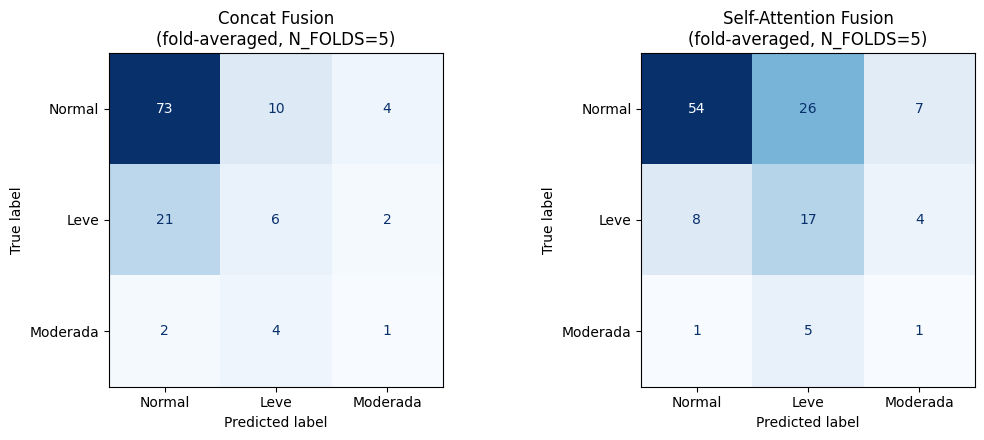

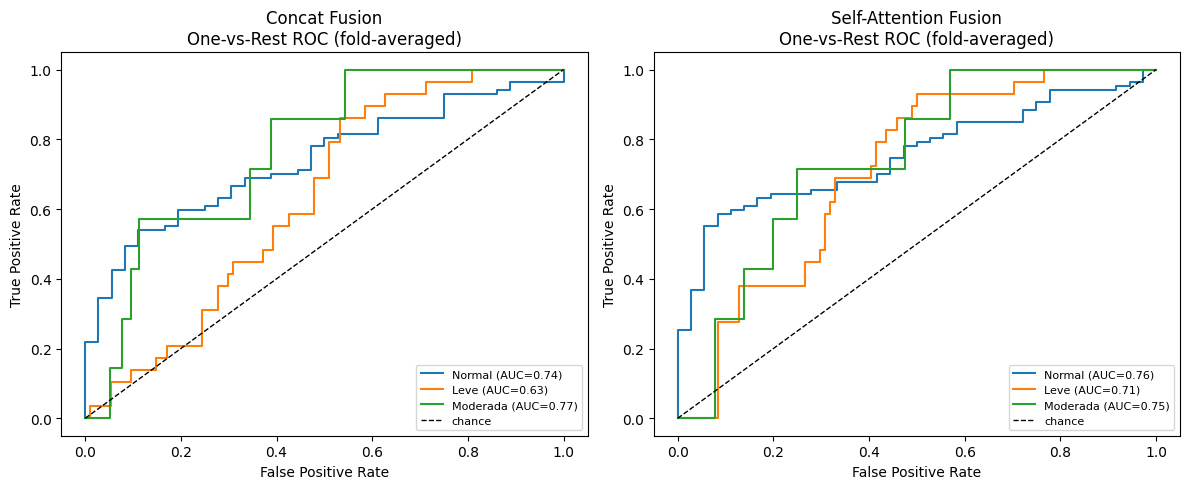

In [20]:
CLASS_NAMES = [IDX_TO_CLASS[i] for i in range(NUM_CLASSES)]
true_labels = test_df["Label"].to_numpy()

ensemble_probs = {fusion_name: np.mean(np.stack(fold_test_probs[fusion_name], axis=0), axis=0)
                   for fusion_name in ["concat", "self_attention"]}
ensemble_preds = {fusion_name: probs.argmax(axis=1) for fusion_name, probs in ensemble_probs.items()}
ensemble_cms = {fusion_name: confusion_matrix(true_labels, preds, labels=list(range(NUM_CLASSES)))
                 for fusion_name, preds in ensemble_preds.items()}

# --- Confusion matrices (fold-averaged / ensembled) ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name, key in [(axes[0], "Concat Fusion", "concat"), (axes[1], "Self-Attention Fusion", "self_attention")]:
    disp = ConfusionMatrixDisplay(confusion_matrix=ensemble_cms[key], display_labels=CLASS_NAMES)
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\n(fold-averaged, N_FOLDS={N_FOLDS})")
plt.tight_layout()
cm_png = os.path.join(RESULTS_DIR, "confusion_matrices_fold_averaged.png")
plt.savefig(cm_png, dpi=150, bbox_inches="tight")
plt.show()

# --- One-vs-rest ROC curves (fold-averaged probabilities) ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name, key in [(axes[0], "Concat Fusion", "concat"), (axes[1], "Self-Attention Fusion", "self_attention")]:
    probs = ensemble_probs[key]
    y_bin = label_binarize(true_labels, classes=list(range(NUM_CLASSES)))
    for c in range(NUM_CLASSES):
        if y_bin[:, c].sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(y_bin[:, c], probs[:, c])
        ax.plot(fpr, tpr, label=f"{CLASS_NAMES[c]} (AUC={sk_auc(fpr, tpr):.2f})")
    ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="chance")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"{name}\nOne-vs-Rest ROC (fold-averaged)")
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
roc_png = os.path.join(RESULTS_DIR, "roc_curves_ovr_fold_averaged.png")
plt.savefig(roc_png, dpi=150, bbox_inches="tight")
plt.show()


Loss curves — concat vs self_attention (combined)

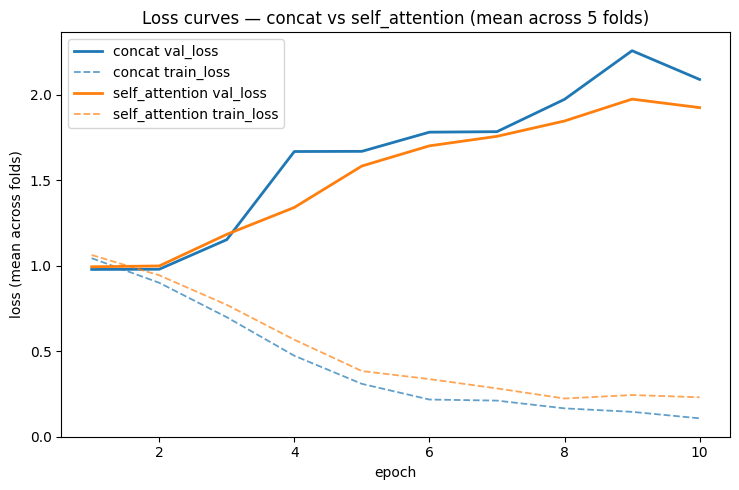

In [21]:
fig, ax = plt.subplots(figsize=(7.5, 5))

colors = {"concat": "tab:blue", "self_attention": "tab:orange"}

for fusion_name in ["concat", "self_attention"]:
    hist_df = pd.concat(fold_histories[fusion_name], ignore_index=True)
    mean_val_loss = hist_df.groupby("epoch")["val_loss"].mean()
    mean_train_loss = hist_df.groupby("epoch")["train_loss"].mean()

    ax.plot(mean_val_loss.index, mean_val_loss.values,
            color=colors[fusion_name], linestyle="-", linewidth=2,
            label=f"{fusion_name} val_loss")
    ax.plot(mean_train_loss.index, mean_train_loss.values,
            color=colors[fusion_name], linestyle="--", linewidth=1.3, alpha=0.7,
            label=f"{fusion_name} train_loss")

ax.set_xlabel("epoch")
ax.set_ylabel("loss (mean across folds)")
ax.set_title(f"Loss curves \u2014 concat vs self_attention (mean across {N_FOLDS} folds)")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "loss_curves_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()


Per-fold F1 comparison

/tmp/ipykernel_49/3685044113.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([concat_f1, selfattn_f1], labels=["concat", "self_attention"], showmeans=True)


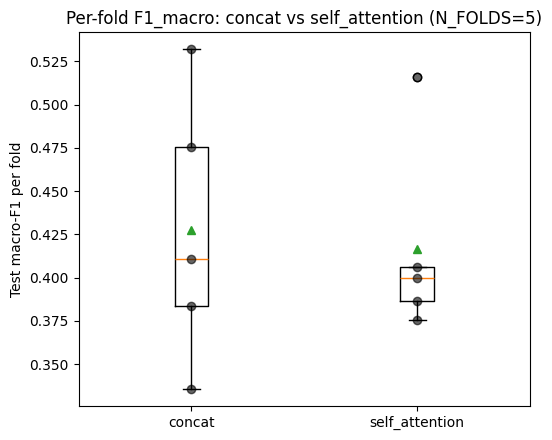

In [22]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
concat_f1 = fold_results_df.loc[fold_results_df["fusion"] == "concat", "f1_macro"].to_numpy()
selfattn_f1 = fold_results_df.loc[fold_results_df["fusion"] == "self_attention", "f1_macro"].to_numpy()
ax.boxplot([concat_f1, selfattn_f1], labels=["concat", "self_attention"], showmeans=True)
for i, scores in enumerate([concat_f1, selfattn_f1], start=1):
    ax.scatter([i] * len(scores), scores, alpha=0.6, color="black", zorder=3)
ax.set_ylabel("Test macro-F1 per fold")
ax.set_title(f"Per-fold F1_macro: concat vs self_attention (N_FOLDS={N_FOLDS})")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "per_fold_f1_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

Cell A — build final_compare_df + save CSV

In [23]:
def ensemble_metrics(key):
    probs = ensemble_probs[key]
    preds = probs.argmax(axis=1)
    acc = accuracy_score(true_labels, preds)
    prec_m, rec_m, f1_m, _ = precision_recall_fscore_support(
        true_labels, preds, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0
    )
    try:
        y_bin = label_binarize(true_labels, classes=list(range(NUM_CLASSES)))
        auc_m = roc_auc_score(y_bin, probs, average="macro", multi_class="ovr")
    except ValueError:
        auc_m = float("nan")
    return {"accuracy": acc, "precision_macro": prec_m, "recall_macro": rec_m,
            "f1_macro": f1_m, "auc_macro_ovr": auc_m}

final_rows = []
for key, label in [("concat", "deep_concat_fusion"), ("self_attention", "deep_self_attention_fusion")]:
    row = {"model": label}
    row.update(ensemble_metrics(key))
    cv_row = cv_summary_df[cv_summary_df["fusion"] == key].iloc[0]
    row["f1_macro_cv_mean"] = cv_row["f1_macro_mean"]
    row["f1_macro_cv_std"] = cv_row["f1_macro_std"]
    final_rows.append(row)

for name, res in tabular_results.items():
    row = {"model": name, "accuracy": res["accuracy"], "precision_macro": res["precision_macro"],
           "recall_macro": res["recall_macro"], "f1_macro": res["f1_macro"],
           "auc_macro_ovr": res["auc_macro_ovr"],
           "f1_macro_cv_mean": res["cv_f1_macro_mean"], "f1_macro_cv_std": res["cv_f1_macro_std"]}
    final_rows.append(row)

final_compare_df = pd.DataFrame(final_rows)
cols = ["model", "accuracy", "precision_macro", "recall_macro", "f1_macro", "auc_macro_ovr",
        "f1_macro_cv_mean", "f1_macro_cv_std"]
print(final_compare_df[cols].to_string(index=False))
final_compare_df.to_csv(os.path.join(RESULTS_DIR, "final_model_comparison.csv"), index=False)

                     model  accuracy  precision_macro  recall_macro  f1_macro  auc_macro_ovr  f1_macro_cv_mean  f1_macro_cv_std
        deep_concat_fusion  0.650407         0.401091      0.396278  0.395190       0.712201          0.427410         0.077260
deep_self_attention_fusion  0.585366         0.431548      0.449918  0.422274       0.737145          0.416807         0.056656
            tabular_logreg  0.479675         0.467829      0.544609  0.406782       0.717370          0.458031         0.044069
                tabular_rf  0.699187         0.406433      0.360153  0.344046       0.699076          0.307843         0.022261


Cell B — plot + save bar chart (must run after Cell A)

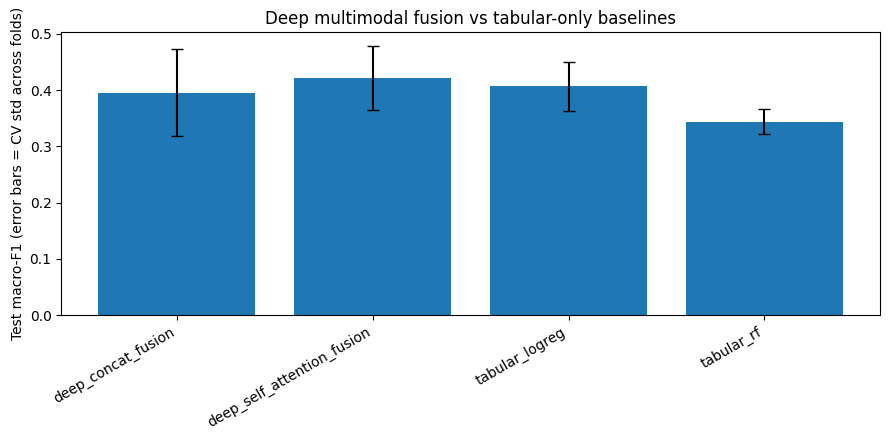


All outputs saved to: /kaggle/working/AnaeCare_results/cv_demo_fusion_test/2026-10-22


In [24]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(final_compare_df))
ax.bar(x, final_compare_df["f1_macro"], yerr=final_compare_df["f1_macro_cv_std"], capsize=4)
ax.set_xticks(x)
ax.set_xticklabels(final_compare_df["model"], rotation=30, ha="right")
ax.set_ylabel("Test macro-F1 (error bars = CV std across folds)")
ax.set_title("Deep multimodal fusion vs tabular-only baselines")
plt.tight_layout()
final_png = os.path.join(RESULTS_DIR, "final_model_comparison_bar.png")
plt.savefig(final_png, dpi=150, bbox_inches="tight")
plt.show()

print("\nAll outputs saved to:", RESULTS_DIR)

## Step 13 — Final Comparison Table: Deep (Concat / Self-Attention) vs Tabular Baselines

Puts the fold-averaged deep-model metrics side by side with the sklearn tabular-only baselines
from Step 7 on the **same fixed test set**, so it's a direct, apples-to-apples comparison of
whether the multimodal image+demographics model earns its complexity over simple structured-data
models.

                     model  accuracy  precision_macro  recall_macro  f1_macro  auc_macro_ovr  f1_macro_cv_mean  f1_macro_cv_std
        deep_concat_fusion  0.650407         0.401091      0.396278  0.395190       0.712201          0.427410         0.077260
deep_self_attention_fusion  0.585366         0.431548      0.449918  0.422274       0.737145          0.416807         0.056656
            tabular_logreg  0.479675         0.467829      0.544609  0.406782       0.717370          0.458031         0.044069
                tabular_rf  0.699187         0.406433      0.360153  0.344046       0.699076          0.307843         0.022261


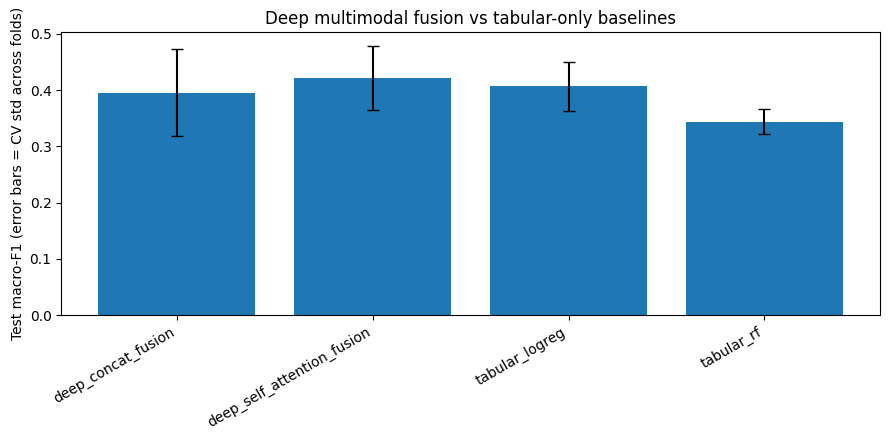


All outputs saved to: /kaggle/working/AnaeCare_results/cv_demo_fusion_test/2026-10-22


In [25]:
def ensemble_metrics(key):
    probs = ensemble_probs[key]
    preds = probs.argmax(axis=1)
    acc = accuracy_score(true_labels, preds)
    prec_m, rec_m, f1_m, _ = precision_recall_fscore_support(
        true_labels, preds, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0
    )
    try:
        y_bin = label_binarize(true_labels, classes=list(range(NUM_CLASSES)))
        auc_m = roc_auc_score(y_bin, probs, average="macro", multi_class="ovr")
    except ValueError:
        auc_m = float("nan")
    return {"accuracy": acc, "precision_macro": prec_m, "recall_macro": rec_m,
            "f1_macro": f1_m, "auc_macro_ovr": auc_m}

final_rows = []
for key, label in [("concat", "deep_concat_fusion"), ("self_attention", "deep_self_attention_fusion")]:
    row = {"model": label}
    row.update(ensemble_metrics(key))
    # also attach the CV mean+-std for context
    cv_row = cv_summary_df[cv_summary_df["fusion"] == key].iloc[0]
    row["f1_macro_cv_mean"] = cv_row["f1_macro_mean"]
    row["f1_macro_cv_std"] = cv_row["f1_macro_std"]
    final_rows.append(row)

for name, res in tabular_results.items():
    row = {"model": name, "accuracy": res["accuracy"], "precision_macro": res["precision_macro"],
           "recall_macro": res["recall_macro"], "f1_macro": res["f1_macro"],
           "auc_macro_ovr": res["auc_macro_ovr"],
           "f1_macro_cv_mean": res["cv_f1_macro_mean"], "f1_macro_cv_std": res["cv_f1_macro_std"]}
    final_rows.append(row)

final_compare_df = pd.DataFrame(final_rows)
cols = ["model", "accuracy", "precision_macro", "recall_macro", "f1_macro", "auc_macro_ovr",
        "f1_macro_cv_mean", "f1_macro_cv_std"]
print(final_compare_df[cols].to_string(index=False))
final_compare_df.to_csv(os.path.join(RESULTS_DIR, "final_model_comparison.csv"), index=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(final_compare_df))
ax.bar(x, final_compare_df["f1_macro"], yerr=final_compare_df["f1_macro_cv_std"], capsize=4)
ax.set_xticks(x); ax.set_xticklabels(final_compare_df["model"], rotation=30, ha="right")
ax.set_ylabel("Test macro-F1 (error bars = CV std across folds)")
ax.set_title("Deep multimodal fusion vs tabular-only baselines")
plt.tight_layout()
final_png = os.path.join(RESULTS_DIR, "final_model_comparison_bar.png")
plt.savefig(final_png, dpi=150, bbox_inches="tight")
plt.show()

print("\nAll outputs saved to:", RESULTS_DIR)


## Step 14 — Zip Everything & Get a Download Link

Bundles every file written to `RESULTS_DIR` this run — per-fold histories/metrics, the CV summary,
the permutation-test result, tabular-baseline results, confusion matrices, ROC curves, the final
comparison table/bar chart, and all per-fold model weights — into a single `.zip` in
`/kaggle/working/`.

In [26]:
import shutil
from IPython.display import FileLink, display

zip_base = os.path.join(RESULTS_DIR_ROOT, f"anaecare_cv_results_{_run_date}")
zip_path = shutil.make_archive(zip_base, "zip", RESULTS_DIR)

print("Files bundled into the zip:")
for root, _, files in os.walk(RESULTS_DIR):
    for fn in sorted(files):
        full = os.path.join(root, fn)
        print(f"  {os.path.relpath(full, RESULTS_DIR)}  ({os.path.getsize(full) / 1024:.1f} KB)")

zip_size_mb = os.path.getsize(zip_path) / (1024 * 1024)
print(f"\nZip written to: {zip_path}  ({zip_size_mb:.1f} MB)")
print("Click below to download it (it's also visible under this notebook's Output tab):")
display(FileLink(os.path.relpath(zip_path, os.getcwd())))


Files bundled into the zip:
  concat_cv_history.csv  (4.3 KB)
  concat_fold1_model.pt  (133550.4 KB)
  concat_fold2_model.pt  (133550.4 KB)
  concat_fold3_model.pt  (133550.4 KB)
  concat_fold4_model.pt  (133550.4 KB)
  concat_fold5_model.pt  (133550.4 KB)
  confusion_matrices_fold_averaged.png  (43.0 KB)
  cv_fold_results.csv  (1.3 KB)
  cv_summary_mean_std.csv  (0.6 KB)
  final_model_comparison.csv  (0.7 KB)
  final_model_comparison_bar.png  (61.0 KB)
  loss_curves_comparison.png  (82.9 KB)
  per_fold_f1_comparison.png  (40.8 KB)
  permutation_test_result.json  (0.1 KB)
  roc_curves_ovr_fold_averaged.png  (86.4 KB)
  self_attention_cv_history.csv  (4.7 KB)
  self_attention_fold1_model.pt  (135172.6 KB)
  self_attention_fold2_model.pt  (135172.6 KB)
  self_attention_fold3_model.pt  (135172.6 KB)
  self_attention_fold4_model.pt  (135172.6 KB)
  self_attention_fold5_model.pt  (135172.6 KB)
  tabular_baseline_results.json  (1.3 KB)

Zip written to: /kaggle/working/anaecare_cv_results_202

/kaggle/working/anaecare_cv_results_2026-10-22.zip